# La promesse de livraison

**Objectif** : promettre au client une date de livraison plus proche que celle d'Olist, sans
augmenter le taux de retard.

**Méthode** : le pipeline minimise cette fois une **perte quantile** au lieu de l'erreur absolue. Il
prédit alors le quantile visé du délai. Avec un quantile de 0,95, environ 95 % des commandes
comparables ont été livrées en moins de temps que la promesse. En faisant varier ce quantile, on
obtient une courbe qui relie le délai promis moyen au taux de retard. Deux promesses se comparent à
taux de retard égal, en lisant le délai promis sur leurs courbes. Le retard est compté au jour près.

Les décisions sont prises sur les mois de validation (sections 1 à 3). Les mois de test sont utilisés
une seule fois, à la fin (section 4), quand plus aucun choix ne reste à faire.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone

from olist_promesse.donnees import charger_commandes, selectionner_commandes
from olist_promesse.evaluation import (
    MOIS_TEST,
    MOIS_VALIDATION,
    delai_promis_a_retard,
    par_mois,
    predire_par_mois,
    quantile_pour_retard,
    resumer_estimation,
    resumer_promesse,
)
from olist_promesse.modeles import QUANTILE_PROMESSE, QuantileParGroupe, modele_gradient_boosting, modele_promesse
from olist_promesse.variables import COLONNES_BRUTES

BLEU, ORANGE, GRIS, GRIS_CLAIR = "#2a78d6", "#eb6834", "#52514e", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.labelcolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.titlelocation": "left",
})

commandes, _ = selectionner_commandes(charger_commandes())
mois_achat = commandes["order_purchase_timestamp"].dt.to_period("M")
effectifs = mois_achat.astype(str).value_counts()
TRAJET = [["seller_state", "customer_state"], ["customer_state"]]
QUANTILES = [q / 100 for q in range(85, 100)]


def detail_par_mois(modele, mois, parametre="quantile"):
    """Taux de retard et délai promis moyen, pour chaque quantile visé et chaque mois évalué."""
    lignes = {}
    for q in QUANTILES:
        promesse = predire_par_mois(clone(modele).set_params(**{parametre: q}), commandes, mois, COLONNES_BRUTES)
        lignes[q] = par_mois(commandes, promesse, resumer_promesse).drop(index="ensemble")
    return pd.concat(lignes, names=["quantile visé", "mois"])


def regrouper(detail, mois):
    """Courbe promesse–retard sur un ensemble de mois, chaque mois pesant son nombre de commandes."""
    poids = effectifs.loc[[str(m) for m in mois]]
    selection = detail[detail.index.get_level_values("mois").isin(poids.index)]
    return selection.mul(poids, level="mois", axis=0).groupby("quantile visé").sum() / poids.sum()


def tracer_courbes(courbes, olist, titre):
    """Courbes promesse–retard des modèles, et point de la promesse d'Olist."""
    fig, ax = plt.subplots()
    for (nom, courbe), couleur in zip(courbes.items(), [GRIS_CLAIR, BLEU]):
        ax.plot(courbe["taux de retard (%)"], courbe["délai promis moyen (j)"], color=couleur, lw=2, label=nom)
    ax.scatter(olist["taux de retard (%)"], olist["délai promis moyen (j)"], color=ORANGE, s=60, zorder=3,
               edgecolor="white", linewidth=2, label="promesse Olist")
    ax.legend(frameon=False)
    ax.set(title=titre, xlabel="taux de retard (%)", ylabel="délai promis moyen (jours)")
    plt.show()

## 1. La promesse par régression quantile

La perte quantile pénalise davantage une promesse trop courte qu'une promesse trop longue. Avec un
quantile de 0,95, un jour de retard coûte 19 fois plus cher qu'un jour de marge (0,95 / 0,05). Le
modèle apprend donc à se couvrir, et d'autant plus que la commande est incertaine.

On trace la courbe du gradient boosting quantile pour des quantiles de 0,85 à 0,99, face à la règle
par trajet et à la promesse d'Olist. Les calculs couvrent aussi les trois mois qui
précèdent la validation, qui serviront à la section 3.

In [2]:
# Les trois mois qui précèdent la validation serviront à la recalibration (section 3).
MOIS_HISTORIQUE = pd.period_range("2017-08", "2018-04", freq="M")
detail_gb = detail_par_mois(modele_gradient_boosting(loss="quantile"), MOIS_HISTORIQUE, parametre="modele__quantile")
detail_trajet = detail_par_mois(QuantileParGroupe(niveaux=TRAJET), MOIS_VALIDATION)
courbes_validation = {
    "quantile par trajet": regrouper(detail_trajet, MOIS_VALIDATION),
    "gradient boosting quantile": regrouper(detail_gb, MOIS_VALIDATION),
}
olist_validation = par_mois(commandes, commandes.loc[mois_achat.isin(MOIS_VALIDATION), "promesse_jours"], resumer_promesse)
retard_olist = olist_validation.loc["ensemble", "taux de retard (%)"]

display(courbes_validation["gradient boosting quantile"].loc[[0.90, 0.95, 0.96, 0.97, 0.98, 0.99]].round(2))
a_retard_egal = {nom: delai_promis_a_retard(courbe, retard_olist) for nom, courbe in courbes_validation.items()}
a_retard_egal["promesse Olist"] = olist_validation.loc["ensemble", "délai promis moyen (j)"]
pd.Series(a_retard_egal, name=f"délai promis moyen (j) à {retard_olist:.2f} % de retard").round(2)

,taux de retard (%),délai promis moyen (j)
quantile visé,,
0.90,21.00,18.20
0.95,13.43,21.97
0.96,11.50,23.33
0.97,9.24,25.16
0.98,6.90,28.04
0.99,3.99,33.34


quantile par trajet           24.17
gradient boosting quantile    23.94
promesse Olist                24.32
Name: délai promis moyen (j) à 10.75 % de retard, dtype: float64

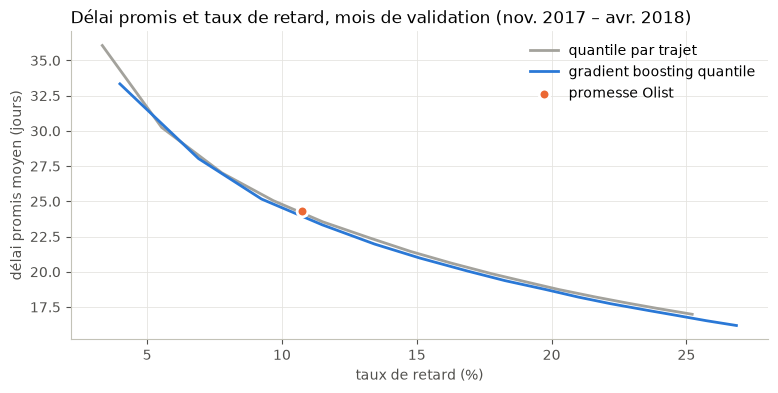

In [3]:
tracer_courbes(courbes_validation, olist_validation.loc["ensemble"],
               "Délai promis et taux de retard, mois de validation (nov. 2017 – avr. 2018)")

Sur les mois de validation, la courbe du gradient boosting passe à peine sous celle de la règle par
trajet. Au taux de retard d'Olist (10,75 %), le modèle promet **23,9 jours**, la règle par trajet
24,2 jours et Olist 24,3 jours : le gain est quasi nul.

Comme déjà observé précédemment, le quantile visé ne garantit pas le taux de retard. Viser 0,95 donne 13,4 % de
retard, et il faut viser 0,98 pour descendre à 6,9 %. Les mois de validation sont plus lents que le
passé dont le modèle apprend. La section suivante regarde où se perd le gain.

## 2. Où le modèle gagne, et où il perd

Pour chaque mois, on lit sur les courbes de ce seul mois le délai que chaque méthode aurait promis
pour être aussi fiable qu'Olist ce mois-là. C'est un diagnostic après coup, puisque le taux de retard
d'Olist n'est pas connu à l'avance.

In [4]:
lignes = {}
for mois in olist_validation.index.drop("ensemble"):
    retard = olist_validation.loc[mois, "taux de retard (%)"]
    lignes[mois] = {
        "taux de retard d'Olist (%)": retard,
        "promesse Olist (j)": olist_validation.loc[mois, "délai promis moyen (j)"],
        "quantile par trajet (j)": delai_promis_a_retard(detail_trajet.xs(mois, level="mois"), retard),
        "gradient boosting quantile (j)": delai_promis_a_retard(detail_gb.xs(mois, level="mois"), retard),
    }
pd.DataFrame.from_dict(lignes, orient="index").round(2)

,taux de retard d'Olist (%),promesse Olist (j),quantile par trajet (j),gradient boosting quantile (j)
2017-11,12.54,22.55,22.79,22.74
2017-12,7.48,27.68,28.51,28.47
2018-01,5.78,26.29,27.51,27.13
2018-02,14.22,24.53,24.20,24.03
2018-03,19.15,21.99,21.93,21.31
2018-04,4.59,23.64,21.75,21.19


Le gradient boosting promet chaque mois un peu moins que la règle par trajet, de 0,04 à 0,6 jour.
Face à Olist, le bilan dépend de la période :
- en février, mars et avril, il promet moins qu'Olist, jusqu'à 2,45 jours de moins en avril,
  mois calme
- de novembre à janvier, il promet plus, de 0,2 à 0,8 jour.

Olist allonge sa promesse pour la fin d'année avec 27,7 jours en décembre contre 22,6 en novembre. Elle
anticipe le pic des fêtes. Le modèle, lui, n'en a jamais vu au 1ᵉʳ décembre 2017 car son historique
commence en janvier 2017. Conclusion : le modèle gagne en période calme et Olist garde l'avantage sur les pics du
calendrier qu'elle connaît, elle.

## 3. Choisir le quantile visé

En production, le quantile visé doit être choisi à l'avance. La règle retenue est la suivante : viser le quantile
qui, sur les mois de validation, donne **le même taux de retard qu'Olist** sur ces mêmes mois
(10,75 %). La promesse est alors aussi fiable que celle d'Olist sur la période où le choix est fait.

In [5]:
quantile_vise = quantile_pour_retard(courbes_validation["gradient boosting quantile"], retard_olist)
print(f"Quantile donnant {retard_olist:.2f} % de retard sur la validation : {quantile_vise:.4f} "
      f"(retenu dans le code : QUANTILE_PROMESSE = {QUANTILE_PROMESSE})")

promesse_validation = predire_par_mois(modele_promesse(), commandes, MOIS_VALIDATION, COLONNES_BRUTES)
pd.concat({
    "promesse Olist": olist_validation,
    f"gradient boosting (quantile {QUANTILE_PROMESSE})": par_mois(commandes, promesse_validation, resumer_promesse),
}, axis=1).round(2)

Quantile donnant 10.75 % de retard sur la validation : 0.9633 (retenu dans le code : QUANTILE_PROMESSE = 0.963)


promesse Olist                         \
         taux de retard (%) délai promis moyen (j)   
2017-11               12.54                  22.55   
2017-12                7.48                  27.68   
2018-01                5.78                  26.29   
2018-02               14.22                  24.53   
2018-03               19.15                  21.99   
2018-04                4.59                  23.64   
ensemble              10.75                  24.32   

         gradient boosting (quantile 0.963)                         
                         taux de retard (%) délai promis moyen (j)  
2017-11                               13.58                  22.01  
2017-12                               15.79                  21.39  
2018-01                                9.10                  22.90  
2018-02                               12.77                  25.05  
2018-03                               12.19                  25.35  
2018-04                                2.37                  25.98  
ensemble                              10.84                  23.83

Le quantile retenu est **0,963**. Sur l'ensemble de la validation, la promesse obtient 10,84 % de
retard pour 23,8 jours, contre 10,75 % et 24,3 jours pour Olist.

Mois par mois, en revanche, le taux de retard varie de 2,4 % (avril) à 15,8 % (décembre). La promesse
du modèle bouge peu, de 21,4 à 26,0 jours, quand celle d'Olist varie de 22,0 à 27,7 jours.

Une question légitime apparaît alors : peut-on mieux tenir le taux de retard en recalibrant chaque mois ? Pour le savoir, on essaie une règle simple qui revient, le
1ᵉʳ de chaque mois, à choisir le plus petit quantile qui aurait donné au plus 10,75 % de retard trois
mois plus tôt.

In [6]:
def quantile_recalibre(mois, cible):
    """Plus petit quantile de la grille dont le taux de retard, trois mois plus tôt, ne dépasse pas la cible."""
    passe = detail_gb.xs(str(mois - 3), level="mois")["taux de retard (%)"]
    admissibles = passe[passe <= cible]
    return admissibles.index.min() if len(admissibles) else max(QUANTILES)


recalibration = {}
for mois in MOIS_VALIDATION:
    q = quantile_recalibre(mois, retard_olist)
    recalibration[str(mois)] = {"quantile visé": q, **detail_gb.loc[(q, str(mois))].to_dict()}
recalibration = pd.DataFrame.from_dict(recalibration, orient="index")
poids = effectifs.loc[recalibration.index]
recalibration.loc["ensemble"] = recalibration.mul(poids, axis=0).sum() / poids.sum()
recalibration.loc["ensemble", "quantile visé"] = None
recalibration.round(3)

,quantile visé,taux de retard (%),délai promis moyen (j)
2017-11,0.87,30.257,15.472
2017-12,0.90,29.006,16.288
2018-01,0.90,17.827,17.836
2018-02,0.98,8.716,28.585
2018-03,0.98,7.508,29.867
2018-04,0.96,2.399,25.616
ensemble,NaN,15.734,22.358


En suivant cette règle, la recalibration fait maintenant **pire** avec 15,7 % de retard sur la validation, et jusqu'à 30 % en novembre et
décembre. C'est assez logique puisqu'elle réagit avec trois mois de décalage :
- en novembre, elle se cale sur août, un mois calme, et promet trop court juste avant le Black
  Friday
- en février et mars, elle se cale sur les mois de fin d'année et devient trop prudente.

Le taux de retard d'un mois est dicté par des évènements que le passé récent n'annonce pas. On retient
donc un quantile fixe, 0,963, inscrit dans le code (`QUANTILE_PROMESSE`). Le suivi du taux de retard
réel reste indispensable en production.

## 4. L'évaluation finale sur les mois de test

Les mois de test, de mai à juillet 2018, sont maintenant utilisés, une seule fois, pour tous les choix
faits sur la validation :
- l'estimation : gradient boosting médian
- la promesse : gradient boosting quantile, quantile 0,963
- les références : règle par trajet et promesse d'Olist.

Aucune décision n'est modifiée après cette évaluation.

In [7]:
estimations = {
    "médiane par trajet": predire_par_mois(QuantileParGroupe(niveaux=TRAJET), commandes, MOIS_TEST, COLONNES_BRUTES),
    "gradient boosting": predire_par_mois(modele_gradient_boosting(), commandes, MOIS_TEST, COLONNES_BRUTES),
}
pd.concat({nom: par_mois(commandes, p, resumer_estimation) for nom, p in estimations.items()}, axis=1).round(2)

médiane par trajet                    gradient boosting  \
                    MAE (j) erreur médiane (j)           MAE (j)   
2018-05                4.91               1.17              4.51   
2018-06                4.19               2.76              3.82   
2018-07                4.57               3.18              4.03   
ensemble               4.57               2.45              4.13   

                             
         erreur médiane (j)  
2018-05                0.81  
2018-06                2.14  
2018-07                2.33  
ensemble               1.79

**Estimation** : MAE de **4,13 jours, contre 4,57** pour la médiane par trajet (10 % d'erreur en
moins), et le modèle gagne chaque mois. Les erreurs sont plus faibles que sur la validation, car les
mois de test sont calmes. L'erreur médiane est désormais positive (+1,8 jour) car, les délais ayant
baissé par rapport au passé, le modèle les surestime.

In [8]:
detail_gb_test = detail_par_mois(modele_gradient_boosting(loss="quantile"), MOIS_TEST, parametre="modele__quantile")
detail_trajet_test = detail_par_mois(QuantileParGroupe(niveaux=TRAJET), MOIS_TEST)
courbes_test = {
    "quantile par trajet": regrouper(detail_trajet_test, MOIS_TEST),
    "gradient boosting quantile": regrouper(detail_gb_test, MOIS_TEST),
}
olist_test = par_mois(commandes, commandes.loc[mois_achat.isin(MOIS_TEST), "promesse_jours"], resumer_promesse)
retard_olist_test = olist_test.loc["ensemble", "taux de retard (%)"]

a_retard_egal_test = {nom: delai_promis_a_retard(courbe, retard_olist_test) for nom, courbe in courbes_test.items()}
a_retard_egal_test["promesse Olist"] = olist_test.loc["ensemble", "délai promis moyen (j)"]
pd.Series(a_retard_egal_test, name=f"délai promis moyen (j) à {retard_olist_test:.2f} % de retard").round(2)

quantile par trajet           21.61
gradient boosting quantile    20.61
promesse Olist                23.37
Name: délai promis moyen (j) à 3.86 % de retard, dtype: float64

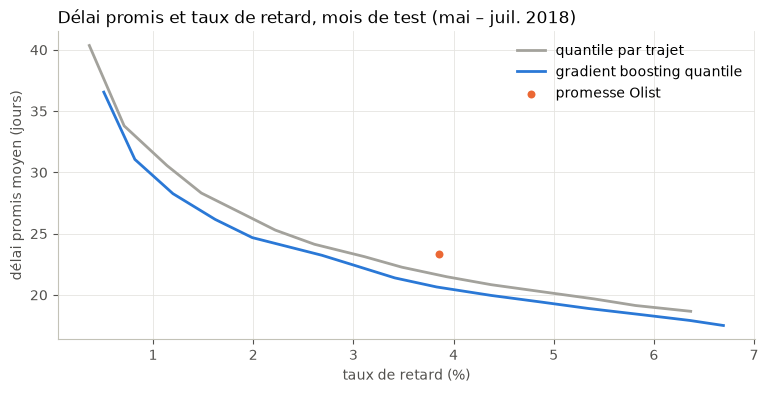

In [9]:
tracer_courbes(courbes_test, olist_test.loc["ensemble"], "Délai promis et taux de retard, mois de test (mai – juil. 2018)")

**Promesse, à taux de retard égal** : au taux de retard d'Olist sur le test (3,86 %), le modèle
promet **20,6 jours, contre 23,4 pour Olist**, soit 2,8 jours de moins (-12 %). La règle par
trajet promet 21,6 jours, le machine learning apporte un jour de plus que la règle simple. Sa courbe
reste sous celle de la règle sur toute la plage.

On tient ici le résultat principal de ce projet : **à fiabilité égale, une promesse 12 % plus courte** sur ces
trois mois.

In [10]:
promesse_test = predire_par_mois(modele_promesse(), commandes, MOIS_TEST, COLONNES_BRUTES)
print(f"Promesses plus courtes que l'estimation du délai : {(promesse_test < estimations['gradient boosting']).mean():.2%}")
pd.concat({
    "promesse Olist": olist_test,
    f"gradient boosting (quantile {QUANTILE_PROMESSE})": par_mois(commandes, promesse_test, resumer_promesse),
}, axis=1).round(2)

Promesses plus courtes que l'estimation du délai : 0.00%


promesse Olist                         \
         taux de retard (%) délai promis moyen (j)   
2018-05                6.66                  22.85   
2018-06                1.19                  27.71   
2018-07                3.43                  19.65   
ensemble               3.86                  23.37   

         gradient boosting (quantile 0.963)                         
                         taux de retard (%) délai promis moyen (j)  
2018-05                                2.12                  26.65  
2018-06                                1.12                  26.63  
2018-07                                1.16                  26.75  
ensemble                               1.49                  26.67

**Au quantile retenu (0,963)**, la promesse obtient 1,49 % de retard pour 26,7 jours, contre 3,86 %
et 23,4 jours pour Olist. Elle est 2,6 fois plus fiable, mais plus longue de 3,3 jours. Le quantile,
choisi sur des mois difficiles, est trop prudent pour des mois calmes. Le modèle permettait mieux si le quantile optimal était effectivement choisi :
20,6 jours au taux de retard d'Olist. Cet écart vient du choix du niveau, pas de la qualité du
modèle.

Aucune promesse n'est plus courte que l'estimation du délai de la même commande, l'API pourra
afficher les deux sans incohérence.

## Synthèse et limites

1. **À fiabilité égale, la promesse est 12 % plus courte** sur les mois de test : 20,6 jours contre
   23,4 pour Olist, à 3,86 % de retard. La règle par trajet fait 21,6 jours donc le modèle apporte un
   jour de plus.
2. **Le gain dépend de la période.** Sur les mois de validation, plus difficiles, le modèle égale à
   peine Olist (23,9 contre 24,3 jours). Il gagne en période calme, et perd en fin d'année, un pic
   qu'Olist anticipe et que le modèle n'a pas pu voir dans son historique.
3. **Le choix du quantile est le point faible.** Calé sur la validation (0,963), il est trop prudent
   sur le test (1,5 % de retard pour 26,7 jours). On pourrait alors le recalibrer chaque mois sur le passé mais cela fait pire. Le
   taux de retard d'un mois dépend de chocs très difficiles à prévoir, pour Olist aussi (de 1,2 % à 19,2 % selon
   les mois). Ni un modèle ni le passé ne trouvent une réponse, elle est probablement métier.
4. **L'estimation du délai** gagne 10 % de MAE sur la règle par trajet (4,13 contre 4,57 jours).

**Limites et pistes** :
- ajouter des variables de calendrier connues (fêtes, Black Friday) quand l'historique couvrira plusieurs
  années
- en production, suivre le taux de retard réel sur les commandes livrées, et ajuster le quantile avec
  les équipes métier en anticipant les périodes de pic
- le test ne couvre que trois mois calmes, il faudrait une année complète pour conclure sur toutes
  les saisons.